In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)

In [24]:
# package import
import numpy as np
from numpy import arange
import pandas as pd
from pandas import read_csv
from pandas import set_option
from pandas.plotting import scatter_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error

import ipywidgets as widgets

In [25]:
X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')

y_train = pd.read_csv('y_train.csv').squeeze('columns')
y_test = pd.read_csv('y_test.csv').squeeze('columns')

In [26]:
# Checking training and testing data predictor shapes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
# Checking available predictors
print("\nPredictors:")
print(X_train.columns.tolist())
# Checking target distribution
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

# Checking X_train head
X_train.head()

Training data: (1183, 36)
Testing data: (789, 36)

Predictors:
['sellerRating', 'ClosePrice', 'OpenPrice', 'Category_Antique/Art/Craft', 'Category_Automotive', 'Category_Books', 'Category_Business/Industrial', 'Category_Clothing/Accessories', 'Category_Coins/Stamps', 'Category_Collectibles', 'Category_Computer', 'Category_Electronics', 'Category_EverythingElse', 'Category_Health/Beauty', 'Category_Home/Garden', 'Category_Jewelry', 'Category_Music/Movie/Game', 'Category_Photography', 'Category_Pottery/Glass', 'Category_SportingGoods', 'Category_Toys/Hobbies', 'Currency_EUR', 'Currency_GBP', 'Currency_US', 'Duration_1', 'Duration_3', 'Duration_5', 'Duration_7', 'Duration_10', 'endDay_Sun', 'endDay_Mon', 'endDay_Tue', 'endDay_Wed', 'endDay_Thu', 'endDay_Fri', 'endDay_Sat']

Training target distribution:
Competitive
1    0.540152
0    0.459848
Name: proportion, dtype: float64

Testing target distribution:
Competitive
1    0.541191
0    0.458809
Name: proportion, dtype: float64


,sellerRating,ClosePrice,OpenPrice,Category_Antique/Art/Craft,Category_Automotive,Category_Books,Category_Business/Industrial,Category_Clothing/Accessories,Category_Coins/Stamps,Category_Collectibles,...,Duration_5,Duration_7,Duration_10,endDay_Sun,endDay_Mon,endDay_Tue,endDay_Wed,endDay_Thu,endDay_Fri,endDay_Sat
0,4390.0,41.49,41.49,1,0,0,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
1,1155.0,8.99,8.99,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,0,0
2,2046.0,7.50,7.50,0,0,0,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
3,1266.0,6.79,6.79,0,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
4,1364.0,30.95,30.95,0,1,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0


In [27]:
# Excluding ClosePrice from the data
X_train_model2 = X_train.drop(columns=['ClosePrice'])
X_test_model2 = X_test.drop(columns=['ClosePrice'])

In [28]:
# Verifying the remaining predictors
print("Training data:", X_train_model2.shape)
print("Testing data:", X_test_model2.shape)
print("\nRemaining predictors:")
print(X_train_model2.columns.tolist())

Training data: (1183, 35)
Testing data: (789, 35)

Remaining predictors:
['sellerRating', 'OpenPrice', 'Category_Antique/Art/Craft', 'Category_Automotive', 'Category_Books', 'Category_Business/Industrial', 'Category_Clothing/Accessories', 'Category_Coins/Stamps', 'Category_Collectibles', 'Category_Computer', 'Category_Electronics', 'Category_EverythingElse', 'Category_Health/Beauty', 'Category_Home/Garden', 'Category_Jewelry', 'Category_Music/Movie/Game', 'Category_Photography', 'Category_Pottery/Glass', 'Category_SportingGoods', 'Category_Toys/Hobbies', 'Currency_EUR', 'Currency_GBP', 'Currency_US', 'Duration_1', 'Duration_3', 'Duration_5', 'Duration_7', 'Duration_10', 'endDay_Sun', 'endDay_Mon', 'endDay_Tue', 'endDay_Wed', 'endDay_Thu', 'endDay_Fri', 'endDay_Sat']


In [29]:
X_train_model2.head()

,sellerRating,OpenPrice,Category_Antique/Art/Craft,Category_Automotive,Category_Books,Category_Business/Industrial,Category_Clothing/Accessories,Category_Coins/Stamps,Category_Collectibles,Category_Computer,...,Duration_5,Duration_7,Duration_10,endDay_Sun,endDay_Mon,endDay_Tue,endDay_Wed,endDay_Thu,endDay_Fri,endDay_Sat
0,4390.0,41.49,1,0,0,0,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
1,1155.0,8.99,0,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,0,0
2,2046.0,7.50,0,0,0,0,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
3,1266.0,6.79,0,0,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
4,1364.0,30.95,0,1,0,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0


In [30]:
compact_cols = ['sellerRating', 'OpenPrice', 'Category_Music/Movie/Game']
ultra_compact_cols = ['sellerRating', 'OpenPrice']

In [31]:
X_train_compact = X_train[compact_cols].values
X_train_ultra_compact = X_train[ultra_compact_cols].values

In [32]:
feature_sets = {
    "all_36": X_train_model2,
    "compact_model": X_train_compact,
}

In [33]:
num_folds = 10
seed = 42


kfold = StratifiedKFold(n_splits=num_folds, random_state=seed, shuffle=True)

model = KNeighborsClassifier()
weighted_model_euclidean = KNeighborsClassifier(weights='distance')
weighted_model_manhattan = KNeighborsClassifier(weights='distance', metric="manhattan")
weighted_model_chebyshev = KNeighborsClassifier(weights='distance', metric="chebyshev")

In [34]:
k_values = [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25]
param_grid = dict(n_neighbors=k_values)
mse_scoring = 'neg_mean_squared_error'
balacc_scoring = 'balanced_accuracy'

In [35]:
# k-fold cross validation for each feature set with different models

settings = {
    "uniform":   model,
    "euclidean": weighted_model_euclidean,
    "manhattan": weighted_model_manhattan,
    "chebyshev": weighted_model_chebyshev,
}

rows = []
for name, X_sub in feature_sets.items():
    # scale this model's columns
    rescaledX = StandardScaler().fit_transform(X_sub)

    for setting, estimator in settings.items():
        # try every k with 10-fold CV
        grid = GridSearchCV(estimator=estimator, param_grid=param_grid,
                            scoring=mse_scoring, cv=kfold)
        grid.fit(rescaledX, y_train)

        for k, mean, std in zip(k_values,
                                grid.cv_results_['mean_test_score'],
                                grid.cv_results_['std_test_score']):
            rows.append({"model": name, "setting": setting, "k": k,
                         "cv_mse": -mean, "cv_std": std})

mse_df = pd.DataFrame(rows)
mse_df.head(-5)

,model,setting,k,cv_mse,cv_std
0,all_36,uniform,1,0.348312,0.027192
1,all_36,uniform,3,0.349929,0.032599
2,all_36,uniform,5,0.363488,0.031019
3,all_36,uniform,7,0.358453,0.027805
4,all_36,uniform,9,0.362641,0.026573
...,...,...,...,...,...
94,compact_model,chebyshev,7,0.284083,0.049500
95,compact_model,chebyshev,9,0.284098,0.048980
96,compact_model,chebyshev,11,0.279882,0.046811
97,compact_model,chebyshev,13,0.284126,0.052639


In [36]:
mse_df.to_csv("mse_results.csv", index=False)
mse_df = pd.read_csv("mse_results.csv")

In [37]:
balacc_rows = []
for name, X_sub in feature_sets.items():
    # scale this model's columns
    rescaledX = StandardScaler().fit_transform(X_sub)

    for setting, estimator in settings.items():
        # try every k with 10-fold CV
        grid = GridSearchCV(estimator=estimator, param_grid=param_grid,
                            scoring=balacc_scoring, cv=kfold)
        grid.fit(rescaledX, y_train)

        for k, mean, std in zip(k_values,
                                grid.cv_results_['mean_test_score'],
                                grid.cv_results_['std_test_score']):
            balacc_rows.append({"model": name, "setting": setting, "k": k,
                                "cv_bal_acc": mean, "cv_std": std})

balacc_df = pd.DataFrame(balacc_rows)
balacc_df.head(-5)

,model,setting,k,cv_bal_acc,cv_std
0,all_36,uniform,1,0.649824,0.027265
1,all_36,uniform,3,0.646818,0.034291
2,all_36,uniform,5,0.632433,0.032443
3,all_36,uniform,7,0.637502,0.028920
4,all_36,uniform,9,0.632659,0.027711
...,...,...,...,...,...
94,compact_model,chebyshev,7,0.714915,0.050667
95,compact_model,chebyshev,9,0.714741,0.050517
96,compact_model,chebyshev,11,0.718796,0.048333
97,compact_model,chebyshev,13,0.714456,0.053572


In [38]:
balacc_df.to_csv("balacc_results.csv", index=False)
balacc_df = pd.read_csv("balacc_results.csv")

In [39]:
colors = {"all_36": "C0", "compact_model": "C1"}
styles = {"uniform": "-", "euclidean": "--", "manhattan": "-.", "chebyshev": ":"}

test_sets = {
    "all_36": X_test_model2,
    "compact_model": X_test[compact_cols].values,
}


test_error_rows = []
for name, X_train_sub in feature_sets.items():
    X_test_sub = test_sets[name]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_sub)
    X_test_scaled = scaler.transform(X_test_sub)

    for setting, estimator in settings.items():
        for k in k_values:
            knn = estimator.set_params(n_neighbors=k)
            knn.fit(X_train_scaled, y_train)
            y_pred = knn.predict(X_test_scaled)
            test_error = 1 - accuracy_score(y_test, y_pred)
            test_error_rows.append({
                "model": name,
                "setting": setting,
                "k": k,
                "test_error": test_error,
                "test_accuracy": 1 - test_error,
            })

test_error_df = pd.DataFrame(test_error_rows)

def plot_test_error(models, setting_names):
    if isinstance(models, str):
        models = [models]
    if isinstance(setting_names, str):
        setting_names = [setting_names]

    plt.figure(figsize=(10, 6))
    for name in models:
        for setting in setting_names:
            d = test_error_df[(test_error_df["model"] == name) &
                              (test_error_df["setting"] == setting)]
            plt.plot(d["k"], d["test_error"], styles[setting], marker="o",
                     markersize=3, color=colors[name],
                     label="%s (%s)" % (name, setting))
    plt.xlabel("Number of Neighbors, K")
    plt.ylabel("Test Error (lower is better)")
    plt.xticks(k_values)
    plt.grid(alpha=0.3)
    if models and setting_names:
        plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

model_boxes = {m: widgets.Checkbox(value=(m == "compact_model"), description=m)
               for m in colors}
setting_boxes = {s: widgets.Checkbox(value=(s == "uniform"), description=s)
                 for s in styles}

def plot_from_boxes(**checked):
    selected_models = [m for m in colors if checked[m]]
    selected_settings = [s for s in styles if checked[s]]
    plot_test_error(selected_models, selected_settings)

out = widgets.interactive_output(plot_from_boxes, {**model_boxes, **setting_boxes})

display(widgets.HBox([
    widgets.VBox([widgets.Label("Models")] + list(model_boxes.values())),
    widgets.VBox([widgets.Label("Settings")] + list(setting_boxes.values())),
]), out)

display(test_error_df)

Output()

,model,setting,k,test_error,test_accuracy
0,all_36,uniform,1,0.310520,0.689480
1,all_36,uniform,3,0.320659,0.679341
2,all_36,uniform,5,0.313054,0.686946
3,all_36,uniform,7,0.324461,0.675539
4,all_36,uniform,9,0.328264,0.671736
...,...,...,...,...,...
99,compact_model,chebyshev,17,0.287706,0.712294
100,compact_model,chebyshev,19,0.290241,0.709759
101,compact_model,chebyshev,21,0.292776,0.707224
102,compact_model,chebyshev,23,0.288973,0.711027


In [40]:
test_error_df.to_csv("test_error_results.csv", index=False)

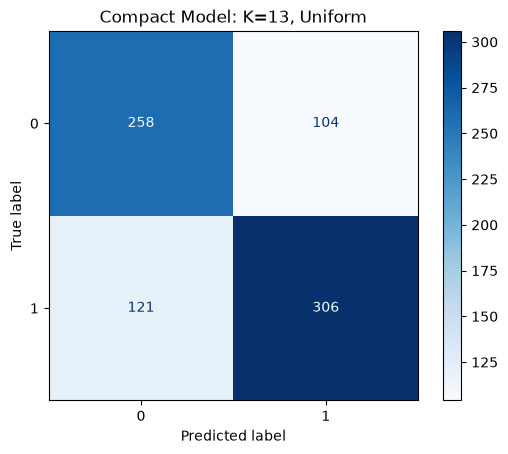

              precision    recall  f1-score   support

           0       0.68      0.71      0.70       362
           1       0.75      0.72      0.73       427

    accuracy                           0.71       789
   macro avg       0.71      0.71      0.71       789
weighted avg       0.72      0.71      0.72       789



In [42]:
# Compact model with K=13 and uniform weighting
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_compact)
X_test_scaled = scaler.transform(X_test[compact_cols].values)

best_knn = KNeighborsClassifier(n_neighbors=13, weights='uniform')
best_knn.fit(X_train_scaled, y_train)

y_pred = best_knn.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Compact Model: K=13, Uniform")
plt.show()

print(classification_report(y_test, y_pred))